# Daily Demand Forecasting: Capital Bikeshare (Washington, DC)

**Author:** Daljeet Kaur
**Tools:** Python (pandas, NumPy, scikit-learn, matplotlib)
**Dataset:** [UCI Bike Sharing Dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset) (Fanaee-T & Gama, 2013): 731 days of Capital Bikeshare rentals (2011–2012) with weather and calendar data.

## Business problem
The operations team plans bike rebalancing trucks, mechanics and station staffing **a week ahead**. Today it plans from last year's numbers, so it is regularly over- or under-staffed. It wants a daily demand forecast that uses the weather forecast and calendar, and a clear picture of what drives demand.

## Objectives
1. Understand demand patterns: trend, seasonality, weekday vs weekend, weather.
2. Build simple **baseline forecasts** the team could use today.
3. Build a **regression model** using calendar and weather features, and measure how much it beats the baselines.
4. Back-test on a held-out quarter (**Oct–Dec 2012**) and translate the error into staffing terms.

*Assumption:* weather inputs come from the next-day weather forecast. Here we use observed weather, so results are an upper bound on real-world accuracy.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (11, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE, GREY, RED, GREEN, ORANGE = "#2563eb", "#9ca3af", "#dc2626", "#16a34a", "#f59e0b"
IMG_DIR, RESULTS_DIR = "../images", "../results"
k = mtick.FuncFormatter(lambda v, _: f"{v/1e3:,.0f}K")

## 1. Load and prepare

In [2]:
raw = pd.read_csv("../data/bike_sharing_daily.csv", parse_dates=["dteday"])
df = raw.rename(columns={"dteday": "date", "cnt": "rentals", "weathersit": "weather", "hum": "humidity"})
# Un-normalize weather to real units (per the UCI data dictionary)
df["temp_c"] = df.temp * 41
df["feels_like_c"] = df.atemp * 50
df["humidity_pct"] = df.humidity * 100
df["wind_kmh"] = df.windspeed * 67
df["weather"] = df.weather.map({1: "Clear", 2: "Mist/Cloudy", 3: "Light rain/snow", 4: "Heavy rain"})
df["day_name"] = df.date.dt.day_name()
print(df.shape, "| missing values:", int(df.isna().sum().sum()), "| dates continuous:",
      (df.date.diff().dropna() == pd.Timedelta(days=1)).all())
df[["date", "rentals", "casual", "registered", "temp_c", "humidity_pct", "wind_kmh", "weather", "workingday"]].head()

(731, 21) | missing values: 0 | dates continuous: True


,date,rentals,casual,registered,temp_c,humidity_pct,wind_kmh,weather,workingday
0,2011-01-01,985,331,654,14.110847,80.5833,10.749882,Mist/Cloudy,0
1,2011-01-02,801,131,670,14.902598,69.6087,16.652113,Mist/Cloudy,0
2,2011-01-03,1349,120,1229,8.050924,43.7273,16.636703,Clear,1
3,2011-01-04,1562,108,1454,8.200000,59.0435,10.739832,Clear,1
4,2011-01-05,1600,82,1518,9.305237,43.6957,12.522300,Clear,1


## 2. Demand patterns

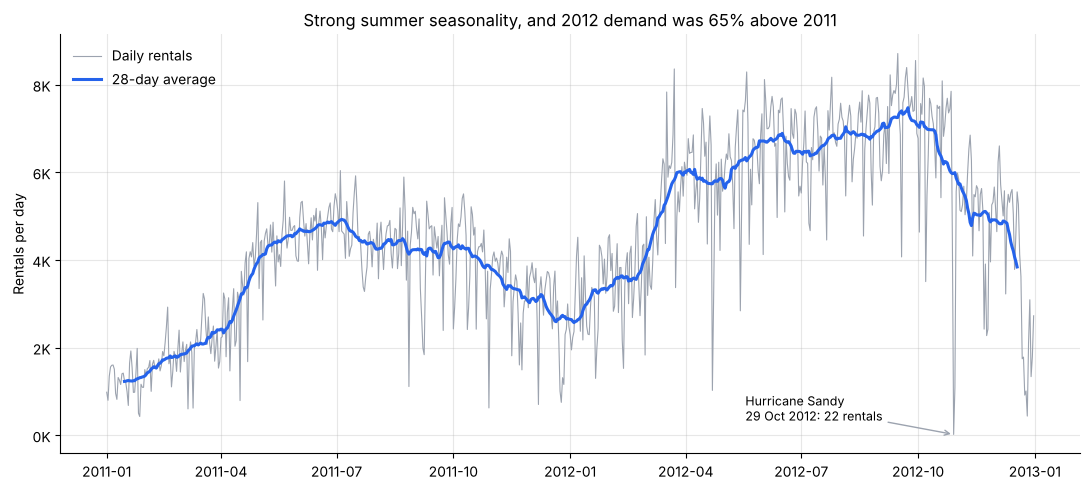

In [3]:
fig, ax = plt.subplots()
ax.plot(df.date, df.rentals, color=GREY, lw=0.8, label="Daily rentals")
ax.plot(df.date, df.rentals.rolling(28, center=True).mean(), color=BLUE, lw=2.2, label="28-day average")
sandy = df.loc[df.rentals.idxmin()]
ax.annotate(f"Hurricane Sandy\n{sandy.date:%d %b %Y}: {sandy.rentals} rentals", (sandy.date, sandy.rentals),
            xytext=(-150, 10), textcoords="offset points", arrowprops=dict(arrowstyle="->", color=GREY), fontsize=9)
ax.yaxis.set_major_formatter(k)
ax.set_ylabel("Rentals per day")
ax.legend(frameon=False, loc="upper left")
growth = df[df.yr == 1].rentals.sum() / df[df.yr == 0].rentals.sum() - 1
ax.set_title(f"Strong summer seasonality, and 2012 demand was {growth:.0%} above 2011")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/01_daily_demand.png", dpi=150)

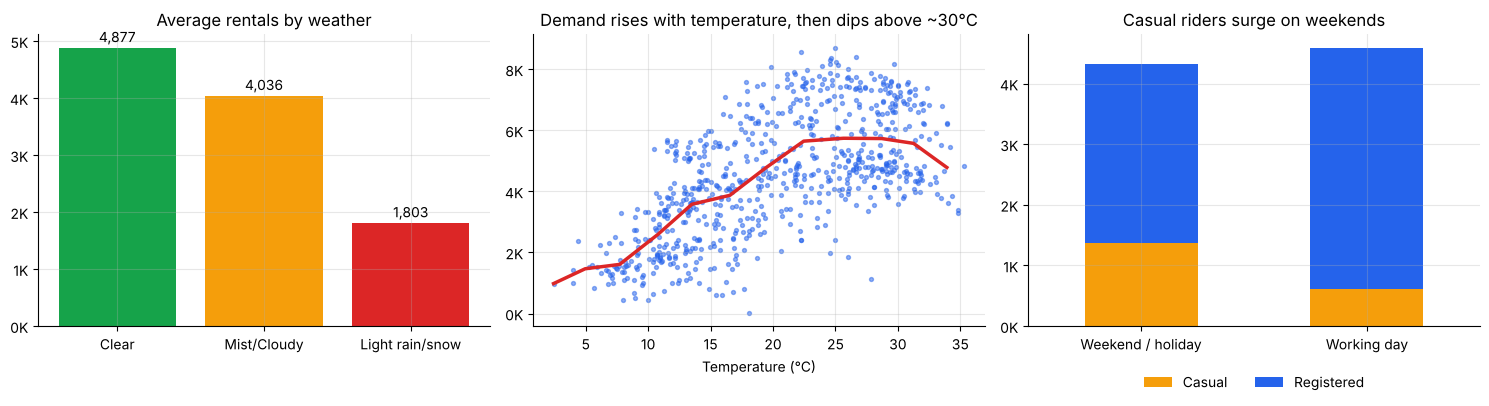

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
w = df.groupby("weather").rentals.mean().reindex(["Clear", "Mist/Cloudy", "Light rain/snow"])
b = axes[0].bar(w.index, w.values, color=[GREEN, ORANGE, RED])
axes[0].bar_label(b, labels=[f"{v:,.0f}" for v in w.values], padding=2)
axes[0].set_title("Average rentals by weather")
axes[0].yaxis.set_major_formatter(k)

axes[1].scatter(df.temp_c, df.rentals, s=8, alpha=0.5, color=BLUE)
t = df.groupby(pd.cut(df.temp_c, np.arange(0, 42, 3)), observed=True).agg(t=("temp_c", "mean"), r=("rentals", "mean"))
axes[1].plot(t.t, t.r, color=RED, lw=2.5)
axes[1].set_title("Demand rises with temperature, then dips above ~30°C")
axes[1].set_xlabel("Temperature (°C)")
axes[1].yaxis.set_major_formatter(k)

mix = df.groupby("workingday")[["casual", "registered"]].mean()
mix.index = ["Weekend / holiday", "Working day"]
mix.plot(kind="bar", stacked=True, ax=axes[2], color=[ORANGE, BLUE], rot=0)
axes[2].set_title("Casual riders surge on weekends")
axes[2].yaxis.set_major_formatter(k)
axes[2].legend(["Casual", "Registered"], frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/02_demand_drivers.png", dpi=150)

In [5]:
print(f"Light rain/snow days average {w['Light rain/snow']:,.0f} rentals vs {w['Clear']:,.0f} on clear days "
      f"({w['Light rain/snow'] / w['Clear'] - 1:.0%})")
print(f"Casual share: weekends {mix.loc['Weekend / holiday', 'casual'] / mix.loc['Weekend / holiday'].sum():.0%} "
      f"vs working days {mix.loc['Working day', 'casual'] / mix.loc['Working day'].sum():.0%}")

Light rain/snow days average 1,803 rentals vs 4,877 on clear days (-63%)
Casual share: weekends 32% vs working days 13%


**Patterns:** Demand grew strongly from 2011 to 2012 and peaks June–September. Rain or snow cuts demand by about 63%. Demand climbs with temperature until about 30°C, then flattens or dips. Total volume is similar on working days and weekends, but on weekends **casual riders make up ~32% of rentals vs ~13% on working days**. That matters for where bikes are needed (tourist areas vs commuter stations).

## 3. Forecast set-up: time-based back-test
Train on **Jan 2011 – Sep 2012**, test on **Oct–Dec 2012** (92 days). A random split would leak future information, so the split is by date.

**Metrics:** MAE (average daily error in bikes), and **WAPE** = total |error| ÷ total actual demand. WAPE is used instead of MAPE because Hurricane Sandy (22 rentals) would make percentage errors explode.

In [6]:
test_start = pd.Timestamp("2012-10-01")
train, test = df[df.date < test_start].copy(), df[df.date >= test_start].copy()
print(f"Train: {len(train)} days ({train.date.min():%b %Y} – {train.date.max():%b %Y}) | Test: {len(test)} days")

def metrics(name, actual, pred):
    err = actual - pred
    return {"model": name, "MAE": np.mean(np.abs(err)), "RMSE": np.sqrt(np.mean(err ** 2)),
            "WAPE": np.sum(np.abs(err)) / np.sum(actual), "Bias": np.sum(pred - actual) / np.sum(actual)}

Train: 639 days (Jan 2011 – Sep 2012) | Test: 92 days


## 4. Baselines (what the team could do today)
1. **Last year, same day:** rentals on the same date in 2011.
2. **Last year × growth:** same date last year, scaled by the year-over-year growth seen in Jan–Sep.
3. **Last week, same weekday:** the actual from 7 days earlier (a 1-week-ahead forecast).

In [7]:
by_date = df.set_index("date").rentals
test["naive_last_year"] = [by_date.get(d - pd.DateOffset(years=1), np.nan) for d in test.date]
ytd_growth = (df[(df.yr == 1) & (df.date < test_start)].rentals.sum()
              / df[(df.yr == 0) & (df.date < test_start - pd.DateOffset(years=1))].rentals.sum())
test["naive_growth"] = test.naive_last_year * ytd_growth
test["naive_last_week"] = [by_date[d - pd.Timedelta(days=7)] for d in test.date]
print(f"Jan–Sep year-over-year growth factor: {ytd_growth:.2f}x")

results = [metrics("Last year, same day", test.rentals, test.naive_last_year),
           metrics("Last year × growth", test.rentals, test.naive_growth),
           metrics("Last week, same weekday", test.rentals, test.naive_last_week)]
pd.DataFrame(results).round(3)

Jan–Sep year-over-year growth factor: 1.69x


,model,MAE,RMSE,WAPE,Bias
0,"Last year, same day",1982.098,2306.237,0.384,-0.341
1,Last year × growth,1287.717,1690.006,0.249,0.115
2,"Last week, same weekday",1457.587,2047.168,0.282,0.085


## 5. Regression models with calendar and weather features
- **Ridge regression:** linear trend + month, weekday, holiday, weather category, plus temperature (with a squared term to capture the heat dip), humidity and wind. Easy to explain.
- **Gradient boosting:** the same inputs, but it can learn non-linear effects and interactions on its own.

In [8]:
def features(d):
    X = pd.DataFrame(index=d.index)
    X["trend"] = (d.date - df.date.min()).dt.days
    X["temp_c"], X["temp_c2"] = d.temp_c, d.temp_c ** 2
    X["humidity_pct"], X["wind_kmh"] = d.humidity_pct, d.wind_kmh
    X["holiday"], X["workingday"] = d.holiday, d.workingday
    X["mnth"], X["weekday"], X["weather"] = d.mnth.astype(str), d.weekday.astype(str), d.weather
    return X

cat_cols, num_cols = ["mnth", "weekday", "weather"], ["trend", "temp_c", "temp_c2", "humidity_pct", "wind_kmh", "holiday", "workingday"]
X_train, X_test = features(train), features(test)

ridge = make_pipeline(ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
                                         ("num", StandardScaler(), num_cols)]), Ridge(alpha=1.0))
ridge.fit(X_train, train.rentals)
test["ridge"] = ridge.predict(X_test)

Xg_train, Xg_test = X_train.copy(), X_test.copy()
for c in cat_cols:
    cats = pd.Categorical(features(df)[c]).categories
    Xg_train[c] = pd.Categorical(Xg_train[c], categories=cats).codes
    Xg_test[c] = pd.Categorical(Xg_test[c], categories=cats).codes
gbm = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_depth=4, random_state=42,
                                    categorical_features=[Xg_train.columns.get_loc(c) for c in cat_cols])
gbm.fit(Xg_train, train.rentals)
test["gbm_raw"] = gbm.predict(Xg_test)

results += [metrics("Ridge regression", test.rentals, test.ridge),
            metrics("Gradient boosting", test.rentals, test.gbm_raw)]
res = pd.DataFrame(results)
res.round(3)

,model,MAE,RMSE,WAPE,Bias
0,"Last year, same day",1982.098,2306.237,0.384,-0.341
1,Last year × growth,1287.717,1690.006,0.249,0.115
2,"Last week, same weekday",1457.587,2047.168,0.282,0.085
3,Ridge regression,941.705,1328.921,0.182,0.056
4,Gradient boosting,1096.864,1514.817,0.212,0.113


## 6. Back-test results

In [9]:
best = res.loc[res.WAPE.idxmin()]
base = res.loc[res.model == "Last year × growth"].iloc[0]
print(f"Best model: {best.model}: WAPE {best.WAPE:.1%}, MAE {best.MAE:,.0f} bikes/day")
print(f"vs 'last year × growth' baseline: WAPE {base.WAPE:.1%}, MAE {base.MAE:,.0f} "
      f"→ error cut by {1 - best.MAE / base.MAE:.0%}")

Best model: Ridge regression: WAPE 18.2%, MAE 942 bikes/day
vs 'last year × growth' baseline: WAPE 24.9%, MAE 1,288 → error cut by 27%


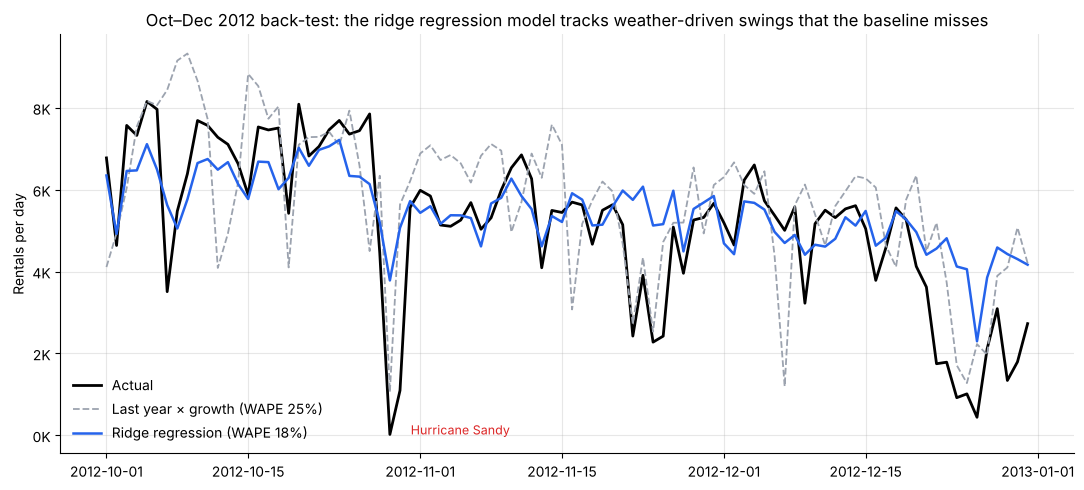

In [10]:
best_col = {"Ridge regression": "ridge", "Gradient boosting": "gbm_raw"}[best.model]
fig, ax = plt.subplots()
ax.plot(test.date, test.rentals, color="black", lw=2, label="Actual")
ax.plot(test.date, test.naive_growth, color=GREY, lw=1.3, ls="--", label=f"Last year × growth (WAPE {base.WAPE:.0%})")
ax.plot(test.date, test[best_col], color=BLUE, lw=1.8, label=f"{best.model} (WAPE {best.WAPE:.0%})")
ax.annotate("Hurricane Sandy", (sandy.date, sandy.rentals), xytext=(15, 0), textcoords="offset points", fontsize=9, color=RED)
ax.yaxis.set_major_formatter(k)
ax.set_ylabel("Rentals per day")
ax.legend(frameon=False, loc="lower left")
ax.set_title(f"Oct–Dec 2012 back-test: the {best.model.lower()} model tracks weather-driven swings that the baseline misses")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/03_backtest_forecast_vs_actual.png", dpi=150)

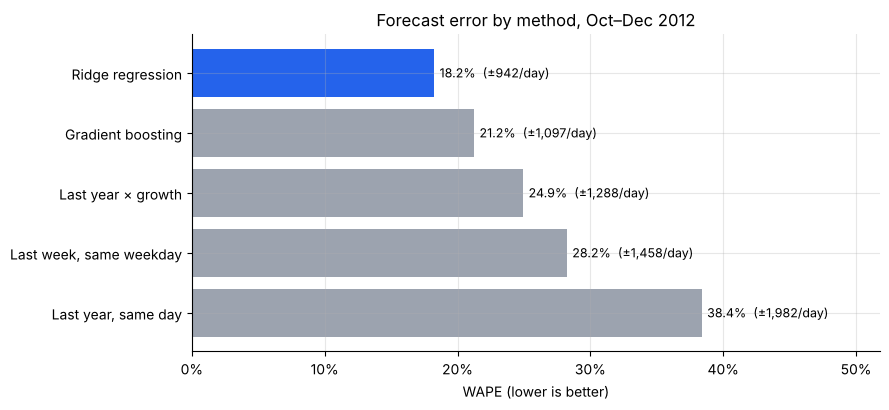

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.2))
r = res.sort_values("WAPE", ascending=False)
bars = ax.barh(r.model, r.WAPE, color=[BLUE if m == best.model else GREY for m in r.model])
ax.bar_label(bars, labels=[f"{v:.1%}  (±{m:,.0f}/day)" for v, m in zip(r.WAPE, r.MAE)], padding=4, fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlim(0, r.WAPE.max() * 1.35)
ax.set_xlabel("WAPE (lower is better)")
ax.set_title("Forecast error by method, Oct–Dec 2012")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/04_model_comparison.png", dpi=150)

## 7. What drives the forecast? (Ridge coefficients)

In [12]:
ohe = ridge.named_steps["columntransformer"]
names = list(ohe.named_transformers_["cat"].get_feature_names_out(cat_cols)) + num_cols
coef = pd.Series(ridge.named_steps["ridge"].coef_, index=names)
weather_eff = coef[[c for c in names if c.startswith("weather_")]]
weather_eff = weather_eff - weather_eff["weather_Clear"]
print("Weather effect vs a clear day (bikes/day, other factors equal):")
print(weather_eff.drop("weather_Clear").round(0).to_string())
print(f"\nTrend: +{coef['trend'] / ridge.named_steps['columntransformer'].named_transformers_['num'].scale_[0] * 365:,.0f} bikes/day per year")

Weather effect vs a clear day (bikes/day, other factors equal):
weather_Light rain/snow   -1670.0
weather_Mist/Cloudy        -430.0

Trend: +2,063 bikes/day per year


Holding season and temperature constant, a misty day costs about 430 bikes and a rain or snow day about 1,670 bikes versus a clear day. The underlying trend adds roughly 2,000 bikes/day per year. Rebalancing plans should be revised as soon as the forecast changes to rain.

## 8. Errors in operational terms

In [13]:
test["abs_err_best"] = (test.rentals - test[best_col]).abs()
test["abs_err_base"] = (test.rentals - test.naive_growth).abs()
big = 1500
print(f"Days off by more than {big:,} bikes: model {(test.abs_err_best > big).sum()} vs baseline {(test.abs_err_base > big).sum()} of {len(test)}")
print(f"Median daily error: model {test.abs_err_best.median():,.0f} vs baseline {test.abs_err_base.median():,.0f} bikes")
test.nlargest(5, "abs_err_best")[["date", "weather", "rentals", best_col, "naive_growth"]].set_index("date").round(0)

Days off by more than 1,500 bikes: model 16 vs baseline 31 of 92
Median daily error: model 542 vs baseline 977 bikes


,weather,rentals,ridge,naive_growth
date,,,,
2012-10-30,Mist/Cloudy,1096,5070.0,5638.0
2012-10-29,Light rain/snow,22,3784.0,1061.0
2012-11-22,Clear,2425,5753.0,2720.0
2012-12-24,Mist/Cloudy,920,4125.0,1711.0
2012-12-29,Mist/Cloudy,1341,4429.0,4101.0


The model's largest misses are Hurricane Sandy (29–30 Oct), Thanksgiving (22 Nov) and the Christmas week. Ops should override the forecast manually for those.

## 9. Save results

In [14]:
res.round(4).to_csv(f"{RESULTS_DIR}/model_comparison.csv", index=False)
test[["date", "rentals", "naive_last_year", "naive_growth", "naive_last_week", "ridge", "gbm_raw"]].set_index("date").round(0).reset_index() \
    .rename(columns={"gbm_raw": "gradient_boosting"}).to_csv(f"{RESULTS_DIR}/backtest_forecasts_oct_dec_2012.csv", index=False)
weather_eff.drop("weather_Clear").round(1).rename("bikes_vs_clear_day").to_csv(f"{RESULTS_DIR}/weather_effects.csv")
print("Saved results")

Saved results


## Recommendations
1. **Replace the "last year" plan with the regression forecast**, refreshed daily from the weather forecast. In the back-test it cut average daily error by 27% (942 vs 1,288 bikes), halved the median daily error (542 vs 977) and halved the days missed by more than 1,500 bikes (16 vs 31).
2. **Add weather triggers to rebalancing:** when rain is forecast, cut truck shifts and move mechanics to repairs. A rain day removes ~1,670 rentals.
3. **Plan weekends separately:** casual riders are ~32% of weekend demand, so stock tourist and park stations before Saturdays.
4. **Flag holidays and extreme weather for manual review**, since these cause the largest errors.
5. **Next step:** retrain monthly on new data and build an hourly model for station-level rebalancing.

**Limitations:** only two years of history, so the trend is estimated from little data. Observed weather stands in for forecasted weather, so real accuracy will be somewhat lower.